# 05 · Caso 2 — otimização: produção máxima e projeto ótimo do sistema de gas lift

Reprodução da Seção 6.2 do artigo: Tabelas 14 e 15 (produção máxima para reservatórios a
220 e 240 bar) e Tabelas 16–19 (projeto ótimo com custos anualizados de compressor, turbina,
linhas de gás e gás combustível). As variáveis de decisão do projeto são as vazões de óleo e
gás de cada poço e o diâmetro das linhas de gás de cada poço (12 variáveis).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
FIG = ROOT / "docs" / "paper" / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
import json, time
from gaslift import case2_multi_well
from gaslift.optimization import GasLiftProblem, Objective, Reservoir
from gaslift.economics import CostModel, CompressorParameters

matlab = json.load(open(REF / "matlab_optimization_results.json"))
PI = [1.0, 2.5, 1.0, 0.5]

## 6.2.1 · Produção máxima (Tabelas 14 e 15)

In [3]:
def max_production(p_res):
    case = case2_multi_well()
    prob = GasLiftProblem(case, [Reservoir(p_res, pi) for pi in PI], Objective.MAX_PRODUCTION, oil_bounds=(0.2, 20.0), gas_bounds=(0.2, 10.0))
    t0 = time.perf_counter()
    res = prob.solve(prob.initial_vector(3.0, 1.0))
    print(f"P_res = {p_res} bar: {res.n_evaluations} simulations in {time.perf_counter() - t0:.0f} s; total oil {res.oil_rates.sum():.3f} kg/s")
    return res

def production_table(res, key):
    ref = matlab[key]
    df = pd.DataFrame({"Well": [1, 2, 3, 4], "Node": [7, 13, 19, 25], "Productivity index ((kg/s)/bar)": PI,
                       "Downhole pressure (bar)": res.economics.downhole_pressure, "Produced oil (kg/s)": res.oil_rates,
                       "Injected gas (kg/s)": res.gas_rates, "Produced oil MATLAB": ref["q_oil"], "Injected gas MATLAB": ref["q_gas"]}).set_index("Well")
    return df.T

res220 = max_production(220.0)
res240 = max_production(240.0)

P_res = 220.0 bar: 851 simulations in 43 s; total oil 18.486 kg/s


P_res = 240.0 bar: 146 simulations in 11 s; total oil 23.675 kg/s


In [4]:
display(production_table(res220, "case2_maxprod_220bar").rename_axis("Table 14 — 220 bar"))

Well,1,2,3,4
Table 14 — 220 bar,,,,
Node,7.0000,13.0000,19.0000,25.0000
Productivity index ((kg/s)/bar),1.0000,2.5000,1.0000,0.5000
Downhole pressure (bar),215.7910,218.0281,214.8511,211.6051
Produced oil (kg/s),4.2095,4.9297,5.1489,4.1976
Injected gas (kg/s),0.7445,0.8209,0.8958,0.7947
Produced oil MATLAB,4.2039,4.9334,5.1517,4.1966
Injected gas MATLAB,0.7433,0.8221,0.8971,0.7947


In [5]:
display(production_table(res240, "case2_maxprod_240bar").rename_axis("Table 15 — 240 bar"))

Well,1,2,3,4
Table 15 — 240 bar,,,,
Node,7.0000,13.0000,19.0000,25.0000
Productivity index ((kg/s)/bar),1.0000,2.5000,1.0000,0.5000
Downhole pressure (bar),234.5840,237.4309,233.4391,229.4493
Produced oil (kg/s),5.4161,6.4229,6.5610,5.2754
Injected gas (kg/s),0.6813,0.7449,0.8201,0.7367
Produced oil MATLAB,5.4169,6.4219,6.5608,5.2758
Injected gas MATLAB,0.6813,0.7444,0.8199,0.7366


Observações do artigo que podem ser verificadas acima: (1) para poços de mesmo índice de
produtividade e geometria semelhante (1 e 3), o poço mais próximo da plataforma recebe mais
gás e produz mais; (2) para distâncias semelhantes (3 e 4), mais gás vai ao poço de maior
índice; (3) a 240 bar produz-se mais óleo com menos gás injetado.

## 6.2.2 · Projeto ótimo (Tabelas 16–19)

Função objetivo $\Omega_3 = R - AGC - ATCC$. As estimativas iniciais são as soluções de
produção máxima acima, com linhas de gás de 2 in. Limites: diâmetros entre 1 e 4 in.

In [6]:
comp = CompressorParameters()
cost = CostModel()
table16 = pd.Series({
    "Number of compressor stages (n)": comp.stages, "Overall compressor efficiency (η)": comp.efficiency,
    "Polytropic coefficient used in Eq. 31 (γ)": comp.polytropic_exponent, "Suction temperature (K)": comp.suction_temperature,
    "Suction pressure (bar)": comp.suction_pressure, "Molecular weight (kg/kmol)": comp.molecular_weight,
    "Fuel gas cost (USD/Nm³)": cost.gas_price, "Oil price (USD/barrel)": cost.oil_price,
    "Pipe length LG1, LG2 (m)": case2_multi_well().gas_line_length("well_1"), "Pipe length LG3, LG4 (m)": case2_multi_well().gas_line_length("well_3"),
    "Diameter bounds (in)": "1 – 4", "Productivity indexes": str(PI), "Reservoir pressure scenarios (bar)": "220, 240"}, name="Table 16")
table16.to_frame()

,Table 16
Number of compressor stages (n),3
Overall compressor efficiency (η),0.8
Polytropic coefficient used in Eq. 31 (γ),1.4
Suction temperature (K),300.0
Suction pressure (bar),5.0
Molecular weight (kg/kmol),25.0
Fuel gas cost (USD/Nm³),0.1886
Oil price (USD/barrel),51.15
"Pipe length LG1, LG2 (m)",6020.0126
"Pipe length LG3, LG4 (m)",4520.0126


In [7]:
def optimal_design(p_res, start):
    case = case2_multi_well()
    prob = GasLiftProblem(case, [Reservoir(p_res, pi) for pi in PI], Objective.OPTIMAL_DESIGN,
                          oil_bounds=(0.5, 20.0), gas_bounds=(0.1, 4.0), diameter_bounds=(1.0, 4.0))
    x0 = prob.initial_vector(start.oil_rates, start.gas_rates, 2.0)
    t0 = time.perf_counter()
    res = prob.solve(x0)
    print(f"P_res = {p_res} bar: {res.n_evaluations} simulations in {time.perf_counter() - t0:.0f} s; profit {res.economics.profit:.2f} 10⁶ USD/yr")
    return res

des220 = optimal_design(220.0, res220)
des240 = optimal_design(240.0, res240)

P_res = 220.0 bar: 712 simulations in 79 s; profit 210.82 10⁶ USD/yr


P_res = 240.0 bar: 744 simulations in 39 s; profit 273.26 10⁶ USD/yr


In [8]:
def design_tables(r1, r2):
    k1, k2 = matlab["case2_design_220bar"], matlab["case2_design_240bar"]
    dec = {}
    for i in range(4):
        dec[f"Injected gas QG{i+1} (kg/s)"] = (r1.gas_rates[i], r2.gas_rates[i], k1["xopt"][4 + i], k2["xopt"][4 + i])
    for i in range(4):
        dec[f"Oil flow rate QL{i+1} (kg/s)"] = (r1.oil_rates[i], r2.oil_rates[i], k1["xopt"][i], k2["xopt"][i])
    for i in range(4):
        dec[f"Pipe diameter DG{i+1} (in)"] = (r1.diameters_in[i], r2.diameters_in[i], k1["xopt"][8 + i], k2["xopt"][8 + i])
    t17 = pd.DataFrame(dec, index=["Scenario 1 (220 bar)", "Scenario 2 (240 bar)", "Scenario 1 MATLAB", "Scenario 2 MATLAB"]).T
    e1, e2 = r1.economics, r2.economics
    t18 = pd.DataFrame({
        "Scenario 1": [e1.compressor_power, e1.discharge_pressure, e1.compressor_cost, e1.turbine_cost, e1.pipeline_cost, e1.fuel_gas_volume],
        "Scenario 2": [e2.compressor_power, e2.discharge_pressure, e2.compressor_cost, e2.turbine_cost, e2.pipeline_cost, e2.fuel_gas_volume],
        "Scenario 1 MATLAB": [k1["out_CompressorPower"], k1["out_DischargePressure"], k1["out_CompressorCapitalCost"], k1["out_TurbineCapitalCost"], k1["out_PipesCapitalCost"], k1["out_FuelGasFlowRate"]],
        "Scenario 2 MATLAB": [k2["out_CompressorPower"], k2["out_DischargePressure"], k2["out_CompressorCapitalCost"], k2["out_TurbineCapitalCost"], k2["out_PipesCapitalCost"], k2["out_FuelGasFlowRate"]],
        "Unit": ["kW", "bar", "10⁶ USD", "10⁶ USD", "10⁶ USD", "10⁶ m³/yr"]},
        index=["Compressor power (wC)", "Compressor discharge pressure", "Compressor capital cost (CC)", "Turbine capital cost (CT)", "Gas pipelines capital cost (CP)", "Fuel gas flow rate"])
    t19 = pd.DataFrame({
        "Scenario 1": [e1.injected_gas_volume.sum(), e1.oil_volume.sum(), e1.fuel_gas_cost, e1.annualized_capital_cost, e1.isbl, e1.osbl, e1.revenue, e1.profit],
        "Scenario 2": [e2.injected_gas_volume.sum(), e2.oil_volume.sum(), e2.fuel_gas_cost, e2.annualized_capital_cost, e2.isbl, e2.osbl, e2.revenue, e2.profit],
        "Scenario 1 MATLAB": [sum(k1["out_GasLiftFlowRate"]), sum(k1["out_OilFlowRate"]), k1["out_AnnualFuelGasCost"], k1["out_AnnualTotalCapitalCost"], k1["out_ISBL"], k1["out_OSBL"], k1["out_InValue"], k1["out_Profit"]],
        "Scenario 2 MATLAB": [sum(k2["out_GasLiftFlowRate"]), sum(k2["out_OilFlowRate"]), k2["out_AnnualFuelGasCost"], k2["out_AnnualTotalCapitalCost"], k2["out_ISBL"], k2["out_OSBL"], k2["out_InValue"], k2["out_Profit"]],
        "Unit": ["10⁶ m³/yr", "10⁶ barrel/yr", "10⁶ USD/yr", "10⁶ USD/yr", "10⁶ USD", "10⁶ USD", "10⁶ USD/yr", "10⁶ USD/yr"]},
        index=["Total injected gas flow rate", "Total oil flow rate", "Fuel gas cost (AGC)", "Annualized capital cost", "ISBL", "OSBL", "Revenue (R)", "Profit"])
    return t17, t18, t19

table17, table18, table19 = design_tables(des220, des240)
display(table17.rename_axis("Table 17 — decision variables"))

,Scenario 1 (220 bar),Scenario 2 (240 bar),Scenario 1 MATLAB,Scenario 2 MATLAB
Table 17 — decision variables,,,,
Injected gas QG1 (kg/s),0.7052,0.6460,0.7062,0.6469
Injected gas QG2 (kg/s),0.7854,0.7095,0.7847,0.7091
Injected gas QG3 (kg/s),0.8547,0.7807,0.8543,0.7798
Injected gas QG4 (kg/s),0.7530,0.6974,0.7520,0.6973
Oil flow rate QL1 (kg/s),4.1924,5.4068,4.1969,5.4109
Oil flow rate QL2 (kg/s),4.9538,6.4457,4.9518,6.4440
Oil flow rate QL3 (kg/s),5.1518,6.5616,5.1516,6.5589
Oil flow rate QL4 (kg/s),4.1724,5.2459,4.1698,5.2460
Pipe diameter DG1 (in),1.7774,1.6485,1.7747,1.6597


In [9]:
display(table18.rename_axis("Table 18 — pipelines, compressor and turbine"))

,Scenario 1,Scenario 2,Scenario 1 MATLAB,Scenario 2 MATLAB,Unit
"Table 18 — pipelines, compressor and turbine",,,,,
Compressor power (wC),1797.9929,1692.8788,1797.4517,1691.0636,kW
Compressor discharge pressure,235.3915,258.7780,235.4420,258.0174,bar
Compressor capital cost (CC),1.7878,1.7222,1.7874,1.7211,10⁶ USD
Turbine capital cost (CT),3.9476,3.7596,3.9466,3.7563,10⁶ USD
Gas pipelines capital cost (CP),1.0535,0.9772,1.0524,0.9833,10⁶ USD
Fuel gas flow rate,15.1930,14.3048,15.1885,14.2895,10⁶ m³/yr


In [10]:
display(table19.rename_axis("Table 19 — optimal design results"))

,Scenario 1,Scenario 2,Scenario 1 MATLAB,Scenario 2 MATLAB,Unit
Table 19 — optimal design results,,,,,
Total injected gas flow rate,81.4247,74.4670,81.3948,74.4538,10⁶ m³/yr
Total oil flow rate,4.3103,5.5213,4.3102,5.5213,10⁶ barrel/yr
Fuel gas cost (AGC),2.8651,2.6976,2.8643,2.6947,10⁶ USD/yr
Annualized capital cost,6.7888,6.4590,6.7865,6.4607,10⁶ USD/yr
ISBL,6.7888,6.4590,6.7865,6.4607,10⁶ USD
OSBL,20.3665,19.3770,20.3594,19.3821,10⁶ USD
Revenue (R),220.4695,282.4134,220.4665,282.4120,10⁶ USD/yr
Profit,210.8155,273.2567,210.8158,273.2566,10⁶ USD/yr


As pequenas diferenças em relação ao MATLAB (terceira casa decimal) decorrem do otimizador:
a superfície do lucro é muito plana em torno do ótimo, e `fmincon` (2009) e SLSQP param em
pontos ligeiramente distintos com valores de função praticamente iguais.

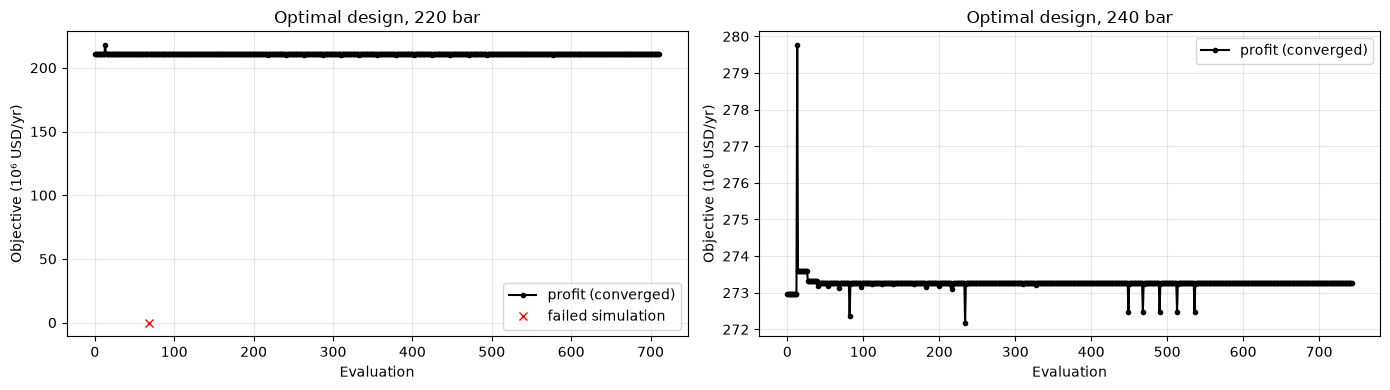

In [11]:
from gaslift.plotting import plot_optimization_history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_optimization_history(des220.history, axes[0]); axes[0].set_title("Optimal design, 220 bar")
plot_optimization_history(des240.history, axes[1]); axes[1].set_title("Optimal design, 240 bar")
plt.tight_layout()